# Figure S5D — GPU speed-up by version

How much faster each metapredict network predicts the human proteome on a GPU than on the CPU of the same machine (ratio of throughputs). The dashed line marks parity (GPU = CPU).

**How it is made.** From the runs in `data/benchmarks/proteome/` (metapredict 3.1.0, default per-device batch size), each GPU run is paired with the CPU run of the same version on the same host, and the speed-up is GPU throughput divided by CPU throughput.

**Output:** `figures/figure_S05D.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import grouped_version_bars, gpu_speedups, proteome_rows, version_legend

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

PARITY = 1.0

In [2]:
speedup = gpu_speedups(proteome_rows())
assert speedup, 'no machine has both a GPU and a CPU run of the same version'
groups = sorted({group for _version, group in speedup})
for (version, group), s in sorted(speedup.items()):
    print(f"{version}  {group.replace(chr(10), ' '):28s} {s:6.2f}x")

proteome: 12 rows from 12 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]
V1  M3 Max MPS vs CPU              0.44x
V1  RTX A4000 CUDA vs CPU          4.88x
V2  M3 Max MPS vs CPU              0.52x
V2  RTX A4000 CUDA vs CPU          8.56x
V3  M3 Max MPS vs CPU              1.66x
V3  RTX A4000 CUDA vs CPU         28.33x


Wrote figures/figure_S05D.pdf


PosixPath('figures/figure_S05D.pdf')

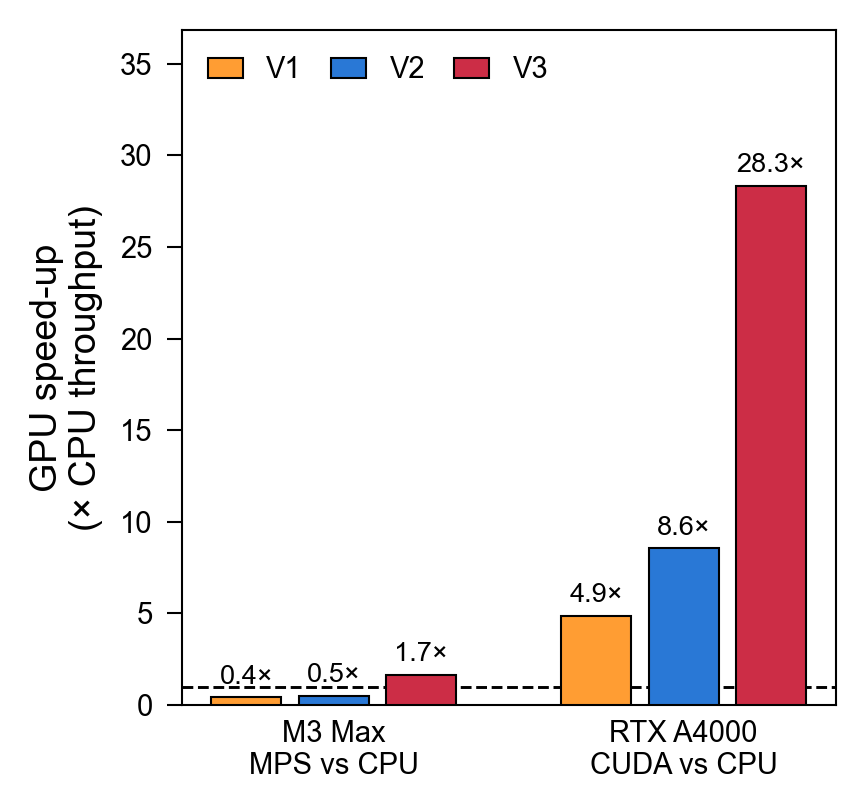

In [3]:
fig, ax = plt.subplots(figsize=(3.0, 2.8), dpi=150)
grouped_version_bars(ax, groups, speedup, label_fmt=lambda v: f'{v:.1f}×')
ax.axhline(PARITY, color='black', linewidth=0.7, linestyle='--', zorder=2)
ax.set_ylim(0, max(max(speedup.values()) * 1.3, PARITY * 1.5))
ax.set_ylabel('GPU speed-up\n(× CPU throughput)', fontsize=9)
version_legend(ax, loc='upper left', ncol=3)
plt.tight_layout()
save_panel(fig, 'figure_S05D')